# Итоговый проект от Мастерской


- Автор: Лагода Максим
- Дата: 30,09,2026

## Описание проекта

Вы работаете аналитиком данных в Яндекс Такси. Каждый день компания обрабатывает миллионы поездок, оплаченных разными способами. Чтобы финансовая и продуктовая команды регулярно получали актуальные данные о выручке и поведении пассажиров, коллеги решили настроить автоматическую обработку этих данных.

Ваша задача — построить витрину данных, которая будет агрегировать информацию о поездках по каждому способу оплаты. Для этого нужно написать PySpark-скрипт, который рассчитает ключевые показатели: количество поездок, среднюю стоимость поездки, средние чаевые и суммарную выручку по каждому типу оплаты.

Чтобы процесс был полностью автоматическим и не зависел от ручных запусков, необходимо создать DAG в Airflow. Этот DAG должен ежедневно:

* проверять наличие новых файлов с данными;

* запускать Spark-задачу;

* формировать обновлённую итоговую таблицу.

Эта таблица станет основой для финансовых отчётов и аналитических дашбордов.

## Описание данных

Таблица `taxi_data` содержит данные об активности пользователей и состоит из следующих полей:

* `taxi_id` — идентификатор водителя;

* `trip_start_timestamp` — время начала поездки;

* `trip_end_timestamp` — время окончания поездки;

* `trip_seconds` — длительность поездки в секундах;

* `trip_miles` — дистанция поездки;

* `fare` — стоимость поездки;

* `tips` — размер чаевых;

* `trip_total` — общая стоимость поездки: стоимость поездки + чаевые + комиссия;

* `payment_type` — способ оплаты.

## Шаг 1. Настройте Spark-агрегацию

Ваши данные для подключения к DBeaver:
* Имя пользователя — username_was_here
* Пароль — password_was_here

Данные хранятся в формате Parquet, поэтому для чтения используйте метод `spark.read.parquet()`. Это быстрее и надёжнее, чем CSV.

Сгруппируйте данные по полю `payment_type` и рассчитайте четыре показателя:

* количество поездок — `count(*)`;
* среднюю стоимость — `avg(...)`;
* средние чаевые — `avg(...)`;
* суммарную выручку — `sum(...)`.

Так получится витрина для анализа информации по каждому способу оплаты. После этого настройте запись полученной таблицы в ClickHouse. Проверьте, что всё работает, и переходите в шагу 2.

Подготовительный шаг: создать целевую таблицу в ClickHouse перед записью данных из Spark.

```sql
CREATE TABLE playground_username_was_here.taxi_payment_summary
(
    `payment_type` String,
    `trip_count` Int64,
    `avg_fare` Float32,
    `avg_tips` Float32,
    `total_revenue` Float32
)
ENGINE = MergeTree
ORDER BY payment_type
SETTINGS index_granularity = 8192;
```

In [ ]:
#filename=my_spark_job2.py

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
SparkSession.builder.appName("TaxiPaymentSummary")
.config("fs.s3a.endpoint", "storage.yandexcloud.net")
.config("spark.dynamicAllocation.enabled", "false")
.config("spark.executor.instances", "1")
.config("spark.executor.cores", "1")
.config("spark.executor.memory", "1g")
.config("spark.driver.memory", "1g")
.getOrCreate()
)

# Указываем порт и параметры кластера ClickHouse
jdbcPort = 8443
jdbcHostname = "hostname_was_here"
username = "username_was_here"
password = "password_was_here"
jdbcDatabase = "database_was_here"
jdbcUrl = f"jdbc:clickhouse://{jdbcHostname}:{jdbcPort}/{jdbcDatabase}?ssl=true"


# Чтение данных из S3
df = spark.read.parquet("s3a://da-plus-dags/project_04/taxi_data.parquet")

# Агрегация
taxi_payment_summary = (
    df.groupBy("payment_type")
      .agg(
          F.count("*").alias("trip_count"),
          F.avg("fare").alias("avg_fare"),
          F.avg("tips").alias("avg_tips"),
          F.sum("trip_total").alias("total_revenue")
      )
)

taxi_payment_summary.write.format("jdbc") \
    .option("url", jdbcUrl) \
    .option("user", username) \
    .option("password", password) \
    .option("dbtable", "taxi_payment_summary") \
    .option("createTableOptions", "ENGINE=MergeTree() ORDER BY payment_type") \
    .mode('overwrite') \
    .save()

## Шаг 2. Настройте DAG

Дату в качестве параметра передавать не нужно. В DAG используйте `S3KeySensor`, чтобы дождаться появления файла в S3. После этого запускайте `DataprocCreatePysparkJobOperator`, передав путь к вашему скрипту. Дополнительный класс-оператор создавать не требуется.

Ваши данные для подключения к Airflow:
* IP — hostname_was_here
* Имя пользователя — username_was_here
* Пароль — password_was_here

In [ ]:
#filename=my_dag.py
from datetime import datetime
from airflow import DAG
from airflow.providers.amazon.aws.sensors.s3 import S3KeySensor
from airflow.providers.yandex.operators.dataproc import DataprocCreatePysparkJobOperator

class PysparkJobOperator(DataprocCreatePysparkJobOperator):
    template_fields = ("cluster_id", "args",)

DAG_ID = "taxi_payment_summary"


with DAG(
    dag_id=DAG_ID,
    start_date=datetime(2025, 1, 1),
    schedule_interval="@daily",
    catchup=False,
) as dag:
    wait_for_input = S3KeySensor(
        task_id="data_s3_sensor",
        bucket_name="da-plus-dags",
        bucket_key="project_04/taxi_data.parquet",
        aws_conn_id="s3",
        poke_interval=300,
        timeout=3600,
        mode="poke",
    )

    run_pyspark = PysparkJobOperator(
        task_id="run_pyspark",
        cluster_id="c9q4134h5vi546h1e148",
        main_python_file_uri=f"s3a://da-plus-dags/username_was_here/jobs/my_spark_job2.py",
    )

    wait_for_input >> run_pyspark

## Шаг 3. Запустите DAG с помощью Airflow UI

Теперь можно переходить к запуску. Нажмите кнопку «Проверить», подождите 5 минут и снова нажмите её. Вам будут показаны данные для входа в веб-интерфейс Airflow. В интерфейсе найдите ваш DAG и запустите его.

Проверьте, что DAG выполнился, а результат соответствует ожиданиям. Если всё получилось — поздравляем, проект завершён!

DAG запущен и успешно выполнен.

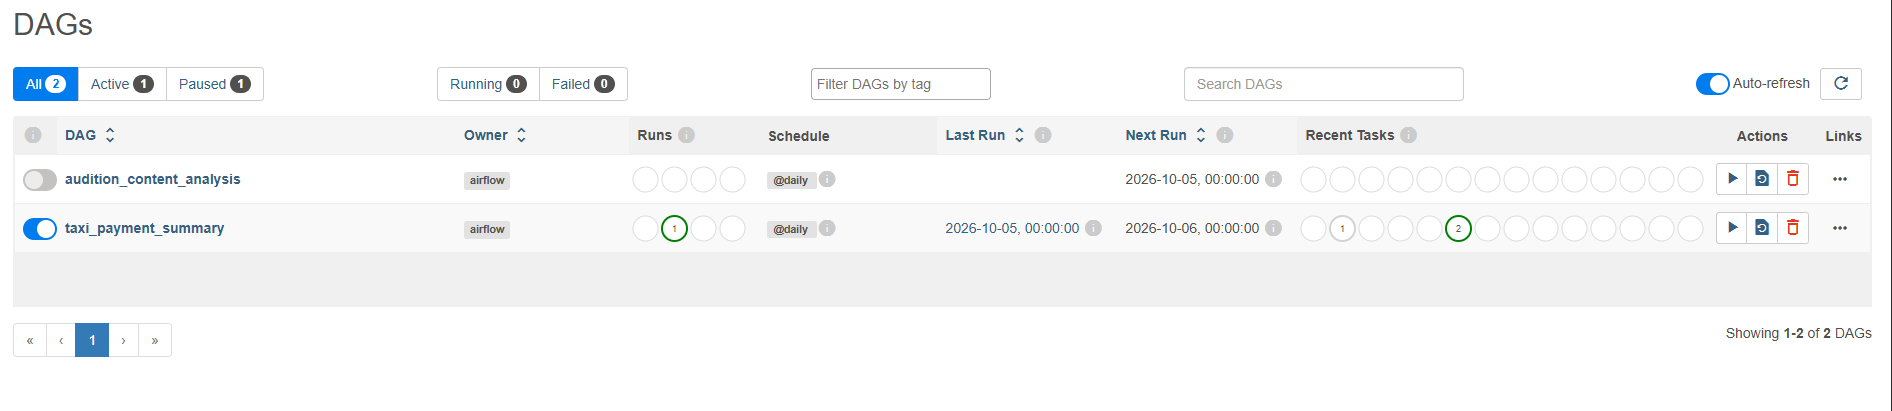

Получена таблица 

|payment_type|trip_count|avg_fare|avg_tips|total_revenue|
|:------------:|:----------:|:--------:|:--------:|:-------------:|
|Cash|1410155|11.194248|0.0033251946|16971150|
|Credit Card|1108843|15.869293|3.477157|23160130|
|Dispute|1842|13.327953|0.0|27052.29|
|No Charge|12843|13.5359535|0.12569416|184374.6|
|Pcard|878|9.833428|0.18314351|9175.55|
|Prcard|968|11.172262|0.25764462|11513.15|
|Unknown|5180|11.791628|0.35713595|67725.07|
|Way2ride|3|3.5|0.79333335|14.38|


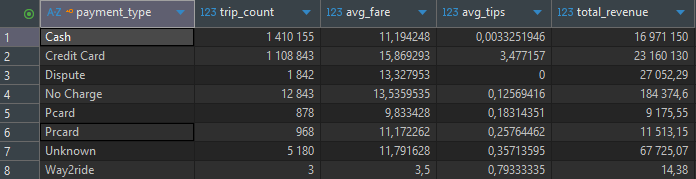